In [2]:

%pip install pandas numpy matplotlib pillow requests imageio-ffmpeg


Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import requests
import imageio_ffmpeg
import subprocess

from pathlib import Path
from PIL import Image
from io import BytesIO
from IPython.display import display
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

REPO = (
    "https://raw.githubusercontent.com/"
    "Geoffreygem/Smartphone-Market-Share-Animation/main"
)

DATA_URL = REPO + "/vendor-ww-monthly-201003-202610.csv"

df = pd.read_csv(DATA_URL)

df["Date"] = pd.to_datetime(
    df["Date"], format="%Y-%m"
)

vendor_cols = [c for c in df.columns if c != "Date"]

df[vendor_cols] = df[vendor_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Exclude all-zero months
df = df.loc[
    df[vendor_cols].sum(axis=1) > 0
].copy()

# Verify no missing vendor figures
if df[vendor_cols].isna().any().any():
    raise ValueError("Some vendor values are missing.")

# Check duplicate dates before removing them
if df["Date"].duplicated().any():
    raise ValueError("Duplicate months detected.")

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset loaded!")
print("Months:", len(df))
print("Start:", df["Date"].min().strftime("%B %Y"))
print("End:", df["Date"].max().strftime("%B %Y"))

display(df.head(3))


Dataset loaded!
Months: 199
Start: April 2010
End: October 2026


,Date,Samsung,Apple,Unknown,Nokia,Xiaomi,Huawei,Oppo,LG,Motorola,...,Sharp,Avea,Karbonn,dtac,Yu,Nothing,Symphony,TCL,Lanix,Other
0,2010-04-01,2.37,33.15,0.0,37.58,0.0,0.0,0.0,0.23,0.30,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67
1,2010-05-01,3.27,33.09,0.0,37.37,0.0,0.0,0.0,0.08,0.12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.66
2,2010-06-01,3.86,30.71,0.0,38.28,0.0,0.0,0.0,0.08,0.11,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.66


In [4]:

selected_brands = [
    "Samsung", "Apple", "Nokia", "Xiaomi",
    "Huawei", "Oppo", "LG", "Motorola",
    "Sony", "Vivo", "HTC", "Lenovo",
    "RIM", "Realme", "Google", "OnePlus",
    "Tecno", "Infinix", "Honor"
]

missing = [
    b for b in selected_brands
    if b not in df.columns
]

if missing:
    raise ValueError(f"Missing brands: {missing}")

remaining = [
    c for c in vendor_cols
    if c not in selected_brands
]

animation_df = df[["Date"] + selected_brands].copy()

animation_df["Other Vendors"] = (
    df[remaining].sum(axis=1)
)

brands = [
    c for c in animation_df.columns
    if c != "Date"
]

values = animation_df[brands].to_numpy(
    dtype=float
)

dates = animation_df["Date"].reset_index(drop=True)

totals = animation_df[brands].sum(axis=1)

print("Brands/categories:", len(brands))
print("Monthly observations:", len(animation_df))
print(
    "Market-share total range:",
    round(totals.min(), 2),
    "to",
    round(totals.max(), 2)
)

display(animation_df.head(3))


Brands/categories: 20
Monthly observations: 199
Market-share total range: 99.92 to 100.04


,Date,Samsung,Apple,Nokia,Xiaomi,Huawei,Oppo,LG,Motorola,Sony,...,HTC,Lenovo,RIM,Realme,Google,OnePlus,Tecno,Infinix,Honor,Other Vendors
0,2010-04-01,2.37,33.15,37.58,0.0,0.0,0.0,0.23,0.30,8.30,...,0.09,0.0,15.86,0.0,0.18,0.0,0.0,0.0,0.0,1.94
1,2010-05-01,3.27,33.09,37.37,0.0,0.0,0.0,0.08,0.12,7.96,...,0.03,0.0,16.16,0.0,0.17,0.0,0.0,0.0,0.0,1.74
2,2010-06-01,3.86,30.71,38.28,0.0,0.0,0.0,0.08,0.11,7.90,...,0.03,0.0,17.23,0.0,0.19,0.0,0.0,0.0,0.0,1.60


In [5]:

logo_files = {
    brand: brand.lower() + ".png"
    for brand in selected_brands
}

LOGO_BASE = REPO + "/assets/logos/"

brand_logos = {}

for brand, filename in logo_files.items():
    try:
        url = LOGO_BASE + filename

        response = requests.get(url, timeout=30)
        response.raise_for_status()

        img = Image.open(
            BytesIO(response.content)
        ).convert("RGBA")

        # Preserve proportions and transparency
        img.thumbnail((84, 84), Image.Resampling.LANCZOS)

        canvas = Image.new(
            "RGBA", (100, 100),
            (0, 0, 0, 0)
        )

        x = (100 - img.width) // 2
        y = (100 - img.height) // 2

        canvas.alpha_composite(img, (x, y))

        brand_logos[brand] = np.array(canvas)

        print("Loaded:", filename)

    except Exception as error:
        print("FAILED:", filename, error)

print()
print("Total logos loaded:", len(brand_logos), "/ 19")

if len(brand_logos) != 19:
    raise RuntimeError(
        "Some logos are missing. Check assets/logos/ on GitHub."
    )


Loaded: samsung.png
Loaded: apple.png
Loaded: nokia.png
Loaded: xiaomi.png
Loaded: huawei.png
Loaded: oppo.png
Loaded: lg.png
Loaded: motorola.png
Loaded: sony.png
Loaded: vivo.png
Loaded: htc.png
Loaded: lenovo.png
Loaded: rim.png
Loaded: realme.png
Loaded: google.png
Loaded: oneplus.png
Loaded: tecno.png
Loaded: infinix.png
Loaded: honor.png

Total logos loaded: 19 / 19


In [6]:

FPS = 30
DURATION = 300
FRAMES = FPS * DURATION
TOP_N = 12

WIDTH = 1920
HEIGHT = 1080
DPI = 100

# Ten sections, each 30 seconds long
SEGMENT_SECONDS = 30
FRAMES_PER_SEGMENT = FPS * SEGMENT_SECONDS
TOTAL_SEGMENTS = 10

BG = "#0D1625"
WHITE = "#FFFFFF"
MUTED = "#A9B7CB"
GOLD = "#F2BE68"

colors = {
    "Samsung": "#356FD1",
    "Apple": "#8D9AAA",
    "Nokia": "#2877C7",
    "Xiaomi": "#FF6900",
    "Huawei": "#D63046",
    "Oppo": "#12A46A",
    "LG": "#C64B75",
    "Motorola": "#5C92FA",
    "Sony": "#65809B",
    "Vivo": "#415FFF",
    "HTC": "#6CB33F",
    "Lenovo": "#E2231A",
    "RIM": "#665B9D",
    "Realme": "#E6A900",
    "Google": "#4285F4",
    "OnePlus": "#EB3447",
    "Tecno": "#2786C9",
    "Infinix": "#00A651",
    "Honor": "#9376D7",
    "Other Vendors": "#778390"
}

# Calculate each month's ranking
monthly_ranks = np.empty_like(values)

for i, row in enumerate(values):
    order = np.argsort(-row, kind="stable")
    monthly_ranks[i, order] = np.arange(len(brands))

# Folder for rendered sections
output_folder = Path("smartphone_rendered_parts")
output_folder.mkdir(exist_ok=True)

mpl.rcParams["animation.ffmpeg_path"] = (
    imageio_ffmpeg.get_ffmpeg_exe()
)

print("FINAL VIDEO SETTINGS")
print("Duration:", DURATION, "seconds")
print("Resolution:", WIDTH, "x", HEIGHT)
print("FPS:", FPS)
print("Total frames:", FRAMES)
print("Sections:", TOTAL_SEGMENTS)
print("Frames per section:", FRAMES_PER_SEGMENT)


FINAL VIDEO SETTINGS
Duration: 300 seconds
Resolution: 1920 x 1080
FPS: 30
Total frames: 9000
Sections: 10
Frames per section: 900


Full five-minute animation design is ready.


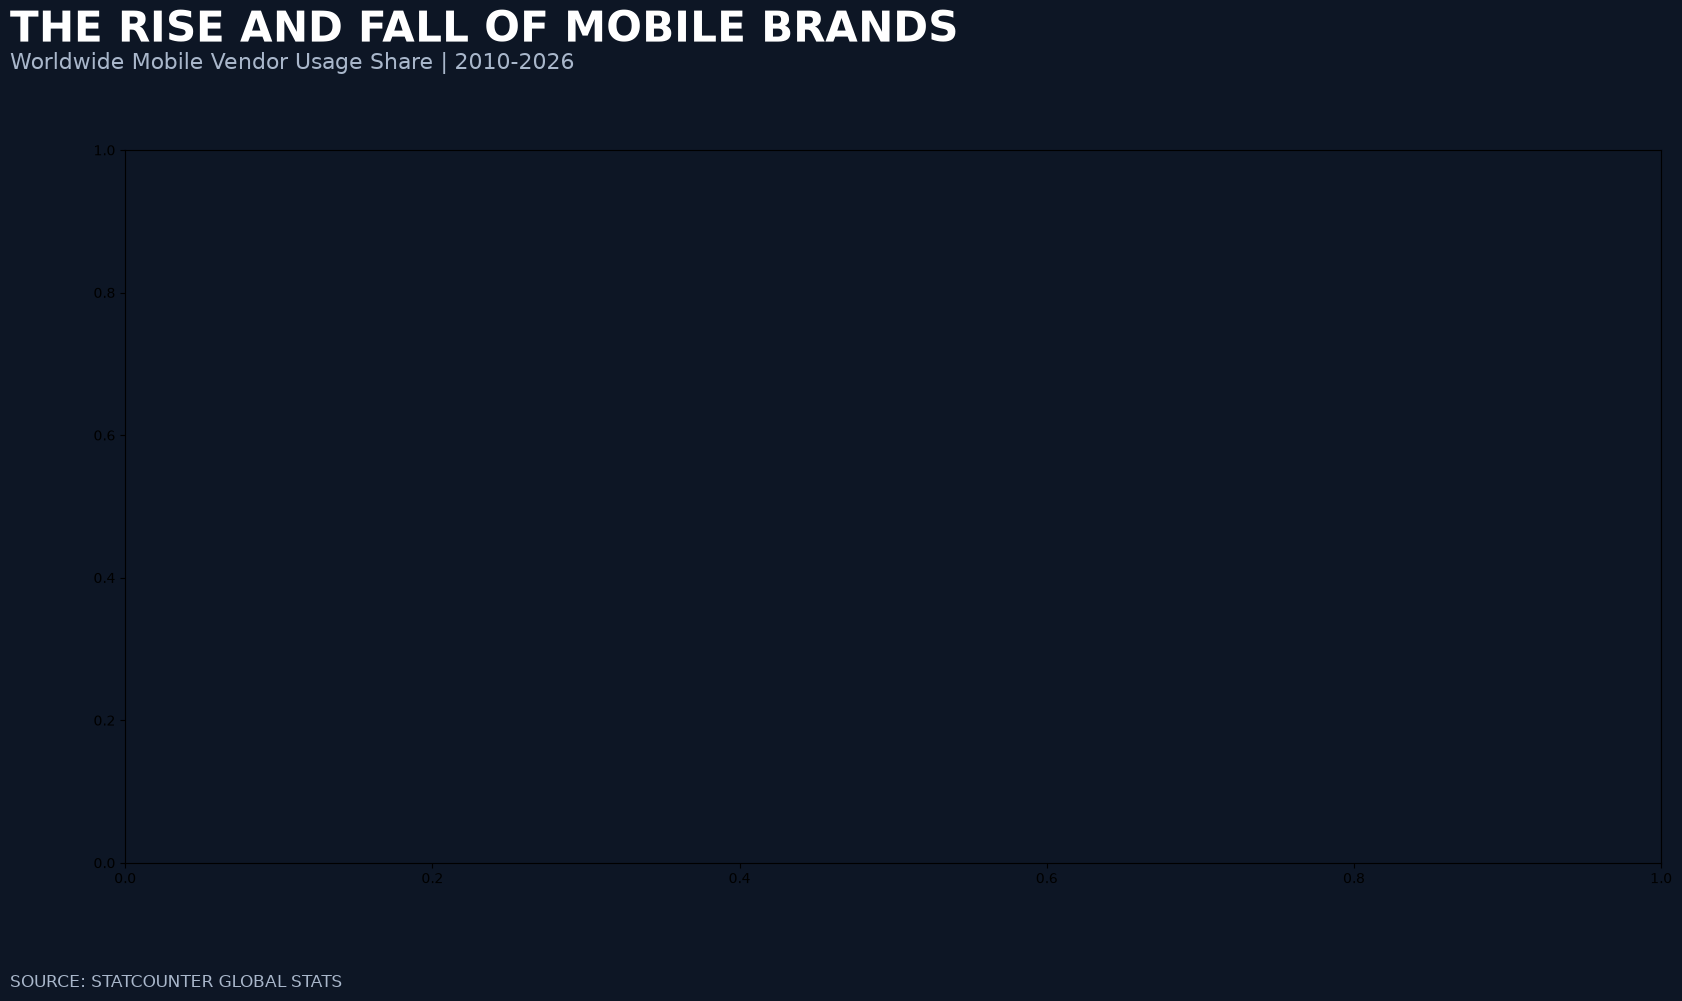

In [7]:

fig = plt.figure(
    figsize=(WIDTH / DPI, HEIGHT / DPI),
    dpi=DPI,
    facecolor=BG
)

ax = fig.add_axes([0.12, 0.16, 0.80, 0.66])
ax.set_facecolor(BG)

fig.text(
    0.06, 0.95,
    "THE RISE AND FALL OF MOBILE BRANDS",
    color=WHITE,
    fontsize=30,
    fontweight="bold",
    va="top"
)

fig.text(
    0.06, 0.895,
    "Worldwide Mobile Vendor Usage Share | 2010-2026",
    color=MUTED,
    fontsize=16
)

fig.text(
    0.06, 0.045,
    "SOURCE: STATCOUNTER GLOBAL STATS",
    color=MUTED,
    fontsize=12
)

date_text = fig.text(
    0.93, 0.07,
    "",
    color=GOLD,
    fontsize=27,
    fontweight="bold",
    ha="right"
)

def add_logo(brand, x, y):
    if brand not in brand_logos:
        return

    logo = OffsetImage(
        brand_logos[brand],
        zoom=0.42
    )

    artist = AnnotationBbox(
        logo,
        (x, y),
        frameon=False,
        box_alignment=(0.5, 0.5),
        annotation_clip=False
    )

    ax.add_artist(artist)


def update(frame):
    ax.clear()
    ax.set_facecolor(BG)

    # Locate this frame within the monthly data
    position = (
        frame / (FRAMES - 1)
    ) * (len(values) - 1)

    index = min(
        int(position),
        len(values) - 2
    )

    fraction = position - index

    current_values = (
        values[index] * (1 - fraction)
        + values[index + 1] * fraction
    )

    current_ranks = (
        monthly_ranks[index] * (1 - fraction)
        + monthly_ranks[index + 1] * fraction
    )

    # Layout
    ax.set_xlim(-24, 65)
    ax.set_ylim(TOP_N - 0.4, -0.8)

    ax.set_xticks([0, 10, 20, 30, 40, 50, 60])
    ax.set_xticklabels(
        ["0%", "10%", "20%", "30%",
         "40%", "50%", "60%"],
        color=MUTED,
        fontsize=12
    )

    ax.set_yticks([])
    ax.tick_params(axis="x", length=0)

    ax.grid(
        axis="x",
        alpha=0.10,
        color="white"
    )
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    for j, brand in enumerate(brands):
        share = float(current_values[j])
        rank = float(current_ranks[j])

        # Only display visible brands
        if share <= 0.005 or rank >= TOP_N:
            continue

        ax.barh(
            rank,
            share,
            color=colors.get(brand, "#888888"),
            height=0.65,
            zorder=2
        )

        add_logo(brand, -21, rank)

        ax.text(
            -18,
            rank,
            brand,
            color=WHITE,
            fontsize=13,
            fontweight="bold",
            va="center",
            ha="left",
            zorder=4
        )

        ax.text(
            min(share + 0.7, 62),
            rank,
            f"{share:.2f}%",
            color=WHITE,
            fontsize=13,
            fontweight="bold",
            va="center",
            zorder=4
        )

    # Date counter
    # The final frame displays the final month
    date_text.set_text(
        dates.iloc[
            index + (1 if fraction >= 0.5 else 0)
        ].strftime("%b %Y")
    )

    return []


print("Full five-minute animation design is ready.")


In [8]:

import re

def video_duration(path):
    """Read duration from FFmpeg without decoding the video."""
    result = subprocess.run(
        [
            imageio_ffmpeg.get_ffmpeg_exe(),
            "-i", str(path)
        ],
        capture_output=True,
        text=True
    )

    match = re.search(
        r"Duration:\s*(\d+):(\d+):(\d+(?:\.\d+)?)",
        result.stderr
    )

    if match is None:
        return None

    hours, minutes, seconds = match.groups()

    return (
        int(hours) * 3600
        + int(minutes) * 60
        + float(seconds)
    )


def render_segment(part_number):
    start = (part_number - 1) * FRAMES_PER_SEGMENT
    end = min(start + FRAMES_PER_SEGMENT, FRAMES)

    filename = output_folder / (
        f"Smartphone_Part_{part_number:02d}.mp4"
    )

    expected_duration = (end - start) / FPS

    # Skip already completed, valid sections
    if filename.exists():
        duration = video_duration(filename)

        if (
            duration is not None
            and abs(duration - expected_duration) < 0.1
        ):
            print(
                f"Part {part_number:02d} already complete.",
                flush=True
            )
            return

        # Remove incomplete output
        filename.unlink()

    print(
        f"Rendering part {part_number}/{TOTAL_SEGMENTS}",
        flush=True
    )

    segment = FuncAnimation(
        fig,
        update,
        frames=range(start, end),
        interval=1000 / FPS,
        repeat=False,
        cache_frame_data=False
    )

    writer = FFMpegWriter(
        fps=FPS,
        bitrate=5000,
        codec="libx264",
        extra_args=[
            "-pix_fmt", "yuv420p",
            "-preset", "ultrafast"
        ]
    )

    segment.save(
        str(filename),
        writer=writer,
        dpi=DPI
    )

    duration = video_duration(filename)

    if (
        duration is None
        or abs(duration - expected_duration) >= 0.1
    ):
        raise RuntimeError(
            f"Part {part_number} did not export fully."
        )

    print(
        f"Completed part {part_number:02d} "
        f"({duration:.1f} seconds)",
        flush=True
    )

    del segment


# Generate all 10 sections
for part in range(1, TOTAL_SEGMENTS + 1):
    render_segment(part)

print()
print("ALL 10 VIDEO SECTIONS EXPORTED!")


Part 01 already complete.
Rendering part 2/10
Completed part 02 (30.0 seconds)
Rendering part 3/10
Completed part 03 (30.0 seconds)
Rendering part 4/10
Completed part 04 (30.0 seconds)
Rendering part 5/10
Completed part 05 (30.0 seconds)
Rendering part 6/10
Completed part 06 (30.0 seconds)
Rendering part 7/10
Completed part 07 (30.0 seconds)
Rendering part 8/10
Completed part 08 (30.0 seconds)
Rendering part 9/10
Completed part 09 (30.0 seconds)
Rendering part 10/10
Completed part 10 (30.0 seconds)

ALL 10 VIDEO SECTIONS EXPORTED!


In [9]:

import subprocess
from pathlib import Path
import imageio_ffmpeg

folder = Path("smartphone_rendered_parts")

# All 10 completed video sections
parts = [
    folder / f"Smartphone_Part_{i:02d}.mp4"
    for i in range(1, 11)
]

# Check every file exists
for part in parts:
    if not part.exists():
        raise FileNotFoundError(f"Missing: {part}")

# Create joining instructions
list_file = Path("smartphone_parts_list.txt")

with open(list_file, "w") as f:
    for part in parts:
        f.write(f"file '{part.resolve()}'\n")

# Combine without re-encoding
subprocess.run([
    imageio_ffmpeg.get_ffmpeg_exe(),
    "-y",
    "-f", "concat",
    "-safe", "0",
    "-i", str(list_file),
    "-c", "copy",
    "-movflags", "+faststart",
    "Smartphone_Brands_FINAL_5min.mp4"
], check=True)

print("FINAL VIDEO CREATED!")


ffmpeg version 7.0.2-static https://johnvansickle.com/ffmpeg/  Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 8 (Debian 8.3.0-6)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-debug --disable-ffplay --disable-indev=sndio --disable-outdev=sndio --cc=gcc --enable-fontconfig --enable-frei0r --enable-gnutls --enable-gmp --enable-libgme --enable-gray --enable-libaom --enable-libfribidi --enable-libass --enable-libvmaf --enable-libfreetype --enable-libmp3lame --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-librubberband --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libvorbis --enable-libopus --enable-libtheora --enable-libvidstab --enable-libvo-amrwbenc --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libdav1d --enable-libxvid --enable-libzvbi --enable-libzimg
  libavutil      59.  8.100 / 59.  8.100
  libavcodec     61.  3.100 / 61.  3.100
  libavformat   

FINAL VIDEO CREATED!


[out#0/mp4 @ 0x268c4b80] video:137299KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.027824%
size=  137337KiB time=00:05:00.00 bitrate=3750.2kbits/s speed=21.6x    
